# S1 · Government collapse, take 2: exact timing, clean events, one trust index

**Why this notebook exists.** The first S1 notebook (`Shock_1_gov_collapse.ipynb`) found almost nothing: ranges as wide as the survey noise, a back-test that did not beat "no change", and a placebo that failed for trust in government. Three weaknesses of the *measurement* (not of the model) are fixed here. The first notebook is left untouched, and so are its `outputs/model/s1_*` files that the dashboard reads. This one writes `outputs/model/s1b_*`.

| Fix | What was wrong | What this notebook does |
| --- | --- | --- |
| **1. Exact timing** | "h = 1" was the next wave, anywhere from 1 to 6 months after the fall, and the baseline was one wave (about 2 points of sampling noise) | The *after* reading is the first wave whose fieldwork **starts 30 to 240 days after the fall**. The baseline is the **mean of the last two waves whose fieldwork ended before it**. A longer window (240 to 420 days) shows whether anything persists. |
| **2. Clean events** | Every fall counted, including ones where an election or another cabinet change landed in the same window, so the reading mixes several shocks | An event is **clean** if, from the last baseline wave to the end of the after wave, there is **no election and no other cabinet ending** in that country. Dropped events are counted and reported, not hidden. Falls are also split by **cause**: coalition break-up, lost vote, scandal or crisis context. |
| **4. One trust index** | Four noisy outcomes, each tested alone | **Trust index** = mean of trust in government, parliament and parties, using only the items available in every wave an event needs. The four single outcomes are still shown. |

**Design.** For each fall, the change in the outcome (after minus baseline) is compared with the same change, **over the same waves**, in EU countries that had **no cabinet ending** in that span (a difference-in-differences against countries not hit). France is excluded everywhere, as in the first notebook (Addendum, point 1). Falls are averaged **within a country first**, then across countries, so Romania's four episodes count once. Ranges are 90% t-ranges across countries.

**Reading rule.** The ±4.4-point survey-noise band in the first notebook applies to *one* episode. An average over many countries is far less noisy, so here the yardstick is the **90% range**: does it include zero, and what size of effect does it rule out?

In [1]:
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUTDIR = ROOT / 'outputs/model'
OUTDIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 40, 'display.width', 220, 'display.max_rows', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
BLUE, GREY, RED, LIGHT, ORANGE = '#2b6cb0', '#8a8f98', '#c53030', '#e8ecf1', '#dd8a2e'

HELD_OUT = 'FRA'
WIN_MAIN, WIN_LATE = (30, 240), (240, 420)       # days after the fall: fieldwork start >= lo, fieldwork centre <= hi
MAX_PRE_GAP = 240                                 # last baseline wave must end within 240 days before the fall
ITEMS = ['trust_gov_pct', 'trust_parl_pct', 'trust_parties_pct']
OUT = {'trust_index': 'Trust index', 'trust_gov': 'Trust in government', 'trust_parl': 'Trust in parliament',
       'trust_parties': 'Trust in parties', 'swd': 'Satisfied with democracy'}
col = lambda o: o if o == 'trust_index' else o + '_pct'

## 1. Data and the cause of each fall

The falls and their dates are the team's reviewed list, as in the first notebook (`s1_all_endings_dataset.csv`). The **cause** is new and is read from the review fields only:

- **scandal or crisis**: the review grouped the fall under a scandal or a financial crisis, or flagged an economic-crisis context;
- **lost a vote**: otherwise, a lost no-confidence, confidence, budget or constructive-censure vote;
- **coalition break-up**: otherwise (a partner left or was dismissed, the prime minister was forced out).

The groups are coarse and partly overlapping in real life (a coalition often breaks up *because of* a scandal). They are a first split, not a typology.

In [2]:
endings = pd.read_csv(ROOT / 'data/processed/s1_all_endings_dataset.csv', parse_dates=['event_date'])
S1_GROUPS = {'government collapse', 'collapse after a scandal', 'collapse in a financial crisis'}
endings['s1_fall'] = endings.case_group.isin(S1_GROUPS) | ((endings.case_group == 'PPEG: cabinet dissension') & (endings.s1_status == 'include'))
falls = endings[endings.s1_fall & (endings.iso3 != HELD_OUT)].copy()

VOTE_TYPES = {'successful_no_confidence_vote', 'confidence_vote_defeat', 'budget_vote_defeat', 'successful_constructive_censure'}
def cause(r):
    fl = str(r.flags) if pd.notna(r.flags) else ''
    if r.case_group in ('collapse after a scandal', 'collapse in a financial crisis') or 'economic_crisis_context' in fl:
        return 'scandal or crisis'
    if r.event_type in VOTE_TYPES or 'lost' in fl:
        return 'lost a vote'
    return 'coalition break-up'
falls['cause'] = falls.apply(cause, axis=1)

with zipfile.ZipFile(ROOT / 'data/raw/ppeg_2025v1/ppeg_gov_2025v1.zip') as z:
    members = pd.read_csv(z.open('ppeg_gov_2025v1.csv'), low_memory=False, usecols=['iso3c', 'iso2c', 'eu_since', 'eu_exit']).drop_duplicates('iso3c')
members = members[members.eu_since.notna()]
iso3_of = dict(zip(members.iso2c, members.iso3c))
with zipfile.ZipFile(ROOT / 'data/raw/ppeg_2025v1/ppeg_parl_2025v1.zip') as z:
    elections = pd.read_csv(z.open('ppeg_parl_2025v1.csv'), usecols=['iso3c', 'edate'], low_memory=False).drop_duplicates()
elections['edate'] = pd.to_datetime(elections.edate)

panel = pd.read_csv(ROOT / 'data/processed/eb_panel.csv', parse_dates=['fieldwork_start', 'fieldwork_end', 'fieldwork_median'])
panel['iso3'] = panel.country.map(iso3_of)
panel = panel.merge(members[['iso3c', 'eu_since', 'eu_exit']], left_on='iso3', right_on='iso3c', how='inner')
yr = panel.fieldwork_median.dt.year
panel = panel[(yr >= panel.eu_since) & (panel.eu_exit.isna() | (yr < panel.eu_exit))]
panel = panel[panel.iso3 != HELD_OUT].sort_values(['iso3', 'fieldwork_start']).reset_index(drop=True)
W = panel.set_index(['za', 'iso3'])

print(f"{len(falls)} falls in {falls.iso3.nunique()} countries (France excluded); {panel.iso3.nunique()} countries and {panel.za.nunique()} waves in the panel")
display(falls.groupby('cause').agg(falls=('episode_id', 'size'), countries=('iso3', 'nunique')))

41 falls in 22 countries (France excluded); 27 countries and 56 waves in the panel


,falls,countries
cause,,
coalition break-up,22,14
lost a vote,11,7
scandal or crisis,8,8


## 2. The method

For one fall in country *c* on date *t*:

1. **Baseline** = mean of the last *n* waves in *c* whose fieldwork **ended before t** (n = 2, or 1 to reproduce the old rule). The last of them must end within 240 days before the fall.
2. **After** = the first wave in *c* whose fieldwork **starts at least `lo` days after t** and whose centre is at most `hi` days after t. (`window=None` reproduces the old rule: first wave centred after the fall.)
3. **Effect of the fall** = (after − baseline) in *c* minus the average of the same quantity, over the **same waves**, in countries with **no cabinet ending** between the first baseline wave and the end of the after wave (at least 5 such countries).
4. **Trust index**: mean of the items (government, parliament, parties) available in all of the event's waves. Controls use the same items.
5. **Clean** event: in *c*, no election from the start of the last baseline wave to the end of the after wave, and no other cabinet ending (failed formations aside) from the start of the first baseline wave to the end of the after wave.
6. **Placebo**: the same, but with the last pre-fall wave as the "after" and the two waves before it as the baseline. It should be about zero.

In [3]:
def t90(df):
    z = 1.6448536
    return z + (z**3 + z) / (4 * df) + (5 * z**5 + 16 * z**3 + 3 * z) / (96 * df**2)

def value(z, k, c, items):
    r = W.loc[(z, k)]
    if c != 'trust_index':
        return r[c]
    v = r[items]
    return np.nan if v.isna().any() else v.mean()

def locate(row, win, n_pre, placebo=False, h=1):
    # (baseline waves, h-th after wave) for one fall, or None if the panel cannot supply them.
    d, t = panel[panel.iso3 == row.iso3], row.event_date
    pre = d[d.fieldwork_end < t]
    if len(pre) < n_pre + (1 if placebo else 0):
        return None
    if (t - pre.fieldwork_end.iloc[-1]).days > MAX_PRE_GAP:
        return None
    if placebo:
        return pre.iloc[-1 - n_pre:-1], pre.iloc[-1]
    if win is None:
        c = d[d.fieldwork_median > t]
    else:
        c = d[(d.fieldwork_start >= t + pd.Timedelta(days=win[0])) & (d.fieldwork_median <= t + pd.Timedelta(days=win[1] + 183 * (h - 1)))]
    return None if len(c) < h else (pre.iloc[-n_pre:], c.iloc[h - 1])

def why_not_clean(row, base, post):
    oth = endings[(endings.iso3 == row.iso3) & (endings.event_date >= base.fieldwork_start.min()) & (endings.event_date <= post.fieldwork_end)
                  & (endings.episode_id != row.episode_id) & (endings.case_group != 'failed government formation')]
    elec = elections[(elections.iso3c == row.iso3) & (elections.edate >= base.fieldwork_start.iloc[-1]) & (elections.edate <= post.fieldwork_end)]
    reasons = (['election'] if len(elec) else []) + (['other cabinet ending'] if len(oth) else [])
    return ' + '.join(reasons)

def event_effects(win, n_pre, clean_only, placebo=False, episodes=None, h=1):
    rows = []
    for r in falls.itertuples():
        if episodes is not None and r.episode_id not in episodes:
            continue
        loc = locate(r, win, n_pre, placebo, h)
        if loc is None:
            continue
        base, post = loc
        reason = why_not_clean(r, base, post)
        if clean_only and reason:
            continue
        s, e = base.fieldwork_start.min(), post.fieldwork_end
        busy = set(endings[(endings.event_date >= s) & (endings.event_date <= e)].iso3)
        ctrl = [c for c in panel.iso3.unique() if c != r.iso3 and c not in busy]
        zs = list(base.za) + [post.za]
        rec = {'episode': r.episode_id, 'iso3': r.iso3, 'cause': r.cause, 'event_date': r.event_date, 'not_clean_because': reason,
               'after_gap_days': (post.fieldwork_median - r.event_date).days,
               'days_no_gov': r.days_until_non_caretaker_cabinet, 'falls_24m': r.early_endings_24m_before,
               'early_election': float(r.next_election_gap_days <= 365),
               'other_endings': int(((endings.iso3 == r.iso3) & (endings.event_date >= s) & (endings.event_date <= e)
                                     & (endings.episode_id != r.episode_id) & (endings.case_group != 'failed government formation')).sum())}
        for o in OUT:
            c = col(o)
            if o == 'trust_index':
                items = [i for i in ITEMS if base[i].notna().all() and pd.notna(post[i])]
                if len(items) < 2:
                    rec[o], rec[o + '_controls'] = np.nan, 0
                    continue
                tv = post[items].mean() - base[items].mean(axis=1).mean()
            else:
                items, tv = None, post[c] - base[c].mean()
            cs = []
            for k in ctrl:
                try:
                    vals = [value(z, k, c, items) for z in zs]
                except KeyError:
                    continue
                if not np.isnan(vals).any():
                    cs.append(vals[-1] - np.mean(vals[:-1]))
            ok = len(cs) >= 5 and not np.isnan(tv)
            rec[o] = tv - np.mean(cs) if ok else np.nan
            rec[o + '_controls'] = len(cs)
        rows.append(rec)
    return pd.DataFrame(rows)

def summarise(ev, by=None, min_countries=3):
    # Country means first, then a t-range across countries.
    out = []
    for name, g in ([('all', ev)] if by is None else list(ev.groupby(by))):
        for o in OUT:
            x = g.dropna(subset=[o])
            cm = x.groupby('iso3')[o].mean()
            n = len(cm)
            m = cm.mean() if n else np.nan
            lo = hi = np.nan
            if n >= min_countries:
                half = t90(n - 1) * cm.std(ddof=1) / np.sqrt(n)
                lo, hi = m - half, m + half
            out.append({'group': name, 'outcome': o, 'events': len(x), 'countries': n, 'effect': m, 'ci_low': lo, 'ci_high': hi})
    return pd.DataFrame(out)

fmt = lambda r: '–' if r.events == 0 else (f"{r.effect:+.1f} ({r.ci_low:+.1f} to {r.ci_high:+.1f})" if pd.notna(r.ci_low) else f"{r.effect:+.1f} (too few countries)")
def show(summary, index='group'):
    t = summary.assign(cell=summary.apply(fmt, axis=1), n=summary.events.astype(str) + ' / ' + summary.countries.astype(str))
    a = t.pivot(index=index, columns='outcome', values='cell')[list(OUT)].rename(columns=OUT)
    b = t.pivot(index=index, columns='outcome', values='n')[list(OUT)].rename(columns=OUT)
    return a, b
print('methods ready')

methods ready


## 3. How many falls survive each filter

The cost of a cleaner measure is sample size, so it is counted first. A fall is lost if the panel cannot give it two baseline waves and an after wave in the window, and it is *not clean* if an election or another cabinet ending falls in its window.

In [4]:
ev_all = event_effects(WIN_MAIN, 2, False)
ev_clean = ev_all[ev_all.not_clean_because == ''].copy()
no_window = sorted(set(falls.episode_id) - set(ev_all.episode))

funnel = pd.DataFrame({
    'step': ['Reviewed falls, France excluded', 'with 2 baseline waves and an after wave 30–240 days later',
             '… of which clean (no election, no other cabinet ending in the window)', '… not clean: election in the window',
             '… not clean: another cabinet ending in the window'],
    'falls': [len(falls), len(ev_all), len(ev_clean),
              int(ev_all.not_clean_because.str.contains('election').sum()), int(ev_all.not_clean_because.str.contains('other').sum())],
    'countries': [falls.iso3.nunique(), ev_all.iso3.nunique(), ev_clean.iso3.nunique(),
                  ev_all[ev_all.not_clean_because.str.contains('election')].iso3.nunique(),
                  ev_all[ev_all.not_clean_because.str.contains('other')].iso3.nunique()]})
display(funnel)
if no_window:
    print('No usable window for:', ', '.join(no_window))
print()
print('Share of the falls followed by an election within the window:', f"{ev_all.not_clean_because.str.contains('election').mean():.0%}")
display(ev_clean.groupby('cause').agg(falls=('episode', 'size'), countries=('iso3', 'nunique')))

,step,falls,countries
0,"Reviewed falls, France excluded",41,22
1,with 2 baseline waves and an after wave 30–240...,40,22
2,"… of which clean (no election, no other cabine...",23,12
3,… not clean: election in the window,11,11
4,… not clean: another cabinet ending in the window,6,5


No usable window for: ROU_200704_Popescu-Tariceanu

Share of the falls followed by an election within the window: 28%


,falls,countries
cause,,
coalition break-up,13,9
lost a vote,7,4
scandal or crisis,3,3


**Selection warning.** Falls followed by an election inside the window are *dropped* from the clean set (the funnel above counts them), so the clean result describes falls that were **not** followed by an election in the window, not falls in general. Section 4 shows the all-falls result next to it.

## 4. What each fix buys

The same method, adding one change at a time. Cells are the **average effect in points** (90% range across countries); the second table is *events / countries*.

In [5]:
STEPS = [
    ('A  Old rule: next wave, 1 baseline wave, all falls', None, 1, False),
    ('B  + 2-wave baseline', None, 2, False),
    ('C  + after wave 30–240 days (all falls)', WIN_MAIN, 2, False),
    ('D  + clean events only', WIN_MAIN, 2, True),
]
step_summ = []
for name, win, n_pre, clean_only in STEPS:
    s = summarise(event_effects(win, n_pre, clean_only))
    step_summ.append(s.assign(group=name))
step_summ = pd.concat(step_summ)
a, b = show(step_summ)
print('Average effect, points (90% range across countries):'); display(a)
print('Events / countries:'); display(b)

w = step_summ.assign(width=step_summ.ci_high - step_summ.ci_low).pivot(index='group', columns='outcome', values='width')[list(OUT)].rename(columns=OUT)
print('Width of the 90% range, points (narrower = more precise):'); display(w.round(1))

Average effect, points (90% range across countries):


outcome,Trust index,Trust in government,Trust in parliament,Trust in parties,Satisfied with democracy
group,,,,,
"A Old rule: next wave, 1 baseline wave, all falls",+1.1 (-2.8 to +5.0),+1.6 (-2.5 to +5.8),+0.7 (-3.5 to +4.9),-0.9 (-3.7 to +1.9),+0.5 (-2.8 to +3.8)
B + 2-wave baseline,+1.3 (-2.2 to +4.8),+1.6 (-2.2 to +5.3),+0.7 (-3.1 to +4.4),-0.5 (-3.2 to +2.1),-0.7 (-4.1 to +2.6)
C + after wave 30–240 days (all falls),+1.9 (-1.5 to +5.3),+2.1 (-1.7 to +6.0),+1.0 (-2.7 to +4.8),-0.1 (-2.5 to +2.3),-0.2 (-3.4 to +3.0)
D + clean events only,-0.5 (-3.5 to +2.5),-0.1 (-4.3 to +4.1),-2.6 (-5.3 to +0.1),-0.7 (-2.3 to +0.8),-2.6 (-5.8 to +0.7)


Events / countries:


outcome,Trust index,Trust in government,Trust in parliament,Trust in parties,Satisfied with democracy
group,,,,,
"A Old rule: next wave, 1 baseline wave, all falls",38 / 21,40 / 22,38 / 21,31 / 19,26 / 17
B + 2-wave baseline,37 / 21,40 / 22,37 / 21,27 / 19,22 / 16
C + after wave 30–240 days (all falls),37 / 21,40 / 22,37 / 21,28 / 19,22 / 16
D + clean events only,20 / 11,23 / 12,20 / 11,15 / 10,12 / 9


Width of the 90% range, points (narrower = more precise):


outcome,Trust index,Trust in government,Trust in parliament,Trust in parties,Satisfied with democracy
group,,,,,
"A Old rule: next wave, 1 baseline wave, all falls",7.8,8.2,8.4,5.7,6.6
B + 2-wave baseline,7.0,7.5,7.6,5.2,6.7
C + after wave 30–240 days (all falls),6.8,7.6,7.5,4.8,6.4
D + clean events only,6.0,8.5,5.4,3.1,6.5


**Reading the steps.** Step B changes only the baseline and narrows the ranges a little. Step C moves the *after* reading to a defined window. Step D drops the falls where an election or another cabinet change lands in the same window. Compare C with D to see how much the election and overlap events move the result; compare widths to see what precision the cleaner design actually bought.

## 5. Main result: clean falls, first wave 30–240 days after

This is the headline table for the dashboard: clean events, exact timing, two-wave baseline. Also shown: the placebo (the same design on the wave **before** the fall, which should be about zero) and the largest effect the data **cannot rule out**.

In [6]:
main = summarise(ev_clean)
plc_ev = event_effects(WIN_MAIN, 2, False, placebo=True, episodes=set(ev_clean.episode))
plc = summarise(plc_ev)
late_ev = event_effects(WIN_LATE, 2, True)
late = summarise(late_ev)
all_c = summarise(ev_all)

tab = pd.DataFrame({
    'Falls / countries': main.apply(lambda r: f"{r.events} / {r.countries}", axis=1).values,
    'Effect, 30–240 d (90% range)': main.apply(fmt, axis=1).values,
    'Largest effect not ruled out': (main[['ci_low', 'ci_high']].abs().max(axis=1)).round(1).values,
    'Placebo, wave before (90% range)': plc.apply(fmt, axis=1).values,
    'Later: 240–420 d (90% range)': late.apply(fmt, axis=1).values,
    'All falls, 30–240 d': all_c.apply(fmt, axis=1).values,
}, index=[OUT[o] for o in main.outcome])
display(tab)

,Falls / countries,"Effect, 30–240 d (90% range)",Largest effect not ruled out,"Placebo, wave before (90% range)",Later: 240–420 d (90% range),"All falls, 30–240 d"
Trust index,20 / 11,-0.5 (-3.5 to +2.5),3.5,-1.0 (-2.6 to +0.7),+0.3 (-3.1 to +3.7),+1.9 (-1.5 to +5.3)
Trust in government,23 / 12,-0.1 (-4.3 to +4.1),4.3,-2.0 (-3.6 to -0.4),-1.5 (-5.9 to +2.9),+2.1 (-1.7 to +6.0)
Trust in parliament,20 / 11,-2.6 (-5.3 to +0.1),5.3,-1.0 (-2.9 to +0.9),+0.2 (-3.6 to +4.1),+1.0 (-2.7 to +4.8)
Trust in parties,15 / 10,-0.7 (-2.3 to +0.8),2.3,+0.5 (-1.4 to +2.5),+1.9 (-0.7 to +4.6),-0.1 (-2.5 to +2.3)
Satisfied with democracy,12 / 9,-2.6 (-5.8 to +0.7),5.8,-1.5 (-3.3 to +0.4),+1.3 (-3.9 to +6.4),-0.2 (-3.4 to +3.0)


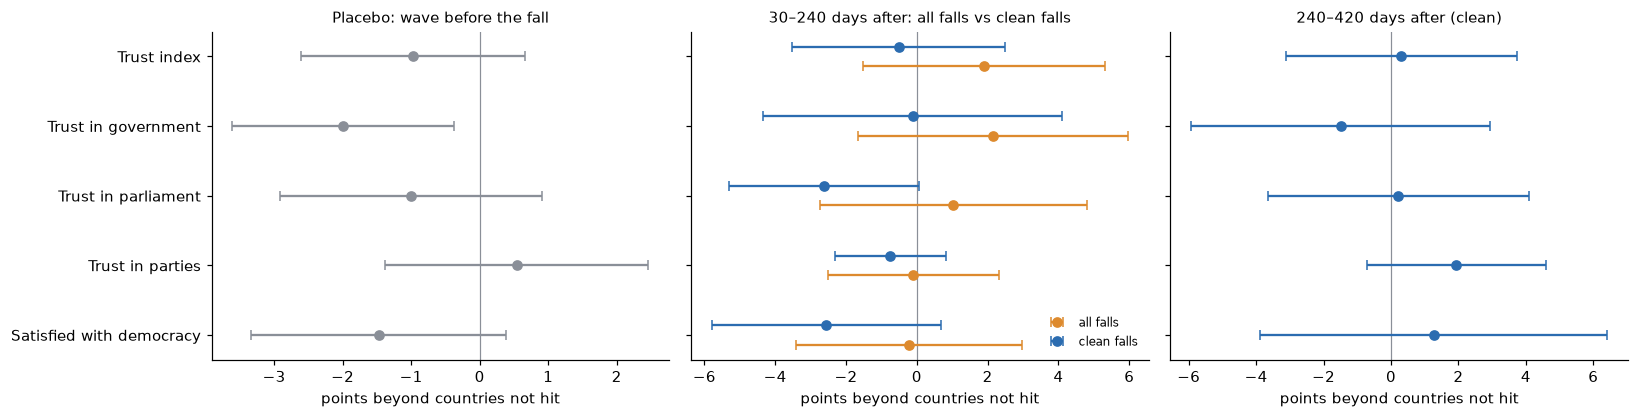

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
for ax, (title, sets) in zip(axes, [('Placebo: wave before the fall', [(plc, GREY)]),
                                     ('30–240 days after: all falls vs clean falls', [(all_c, ORANGE), (main, BLUE)]),
                                     ('240–420 days after (clean)', [(late, BLUE)])]):
    ax.axvline(0, color=GREY, lw=0.8)
    for j, (s, colr) in enumerate(sets):
        off = (j - (len(sets) - 1) / 2) * 0.28
        y = np.arange(len(s))[::-1] + off
        ax.errorbar(s.effect, y, xerr=[s.effect - s.ci_low, s.ci_high - s.effect], fmt='o', color=colr, capsize=3,
                    label={ORANGE: 'all falls', BLUE: 'clean falls', GREY: 'clean falls'}[colr])
    ax.set_yticks(np.arange(len(main))[::-1], [OUT[o] for o in main.outcome])
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('points beyond countries not hit')
    if len(sets) > 1:
        ax.legend(frameon=False, fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

## 6. By cause (exploratory)

The clean falls split by cause. **Treat this as a hypothesis, not a finding**: groups are small, the split was chosen after seeing the pooled result was flat, and 5 outcomes × 3 causes is 15 ranges at 90%, so one or two will exclude zero by chance alone. A group with fewer than 3 countries gets no range. For the group that stands out, the placebo and a leave-one-country-out check follow.

In [8]:
by_cause = summarise(ev_clean, by='cause')
a, b = show(by_cause)
print('Clean falls, 30–240 days after, by cause (90% range):'); display(a)
print('Events / countries:'); display(b)

plc_c = summarise(plc_ev, by='cause')
print('Placebo for the same events (wave before the fall):'); display(show(plc_c)[0])

Clean falls, 30–240 days after, by cause (90% range):


outcome,Trust index,Trust in government,Trust in parliament,Trust in parties,Satisfied with democracy
group,,,,,
coalition break-up,-3.0 (-5.5 to -0.4),-3.8 (-7.6 to -0.1),-4.2 (-7.4 to -1.0),-0.7 (-2.7 to +1.3),-2.1 (-7.1 to +2.9)
lost a vote,+5.9 (-4.0 to +15.7),+5.9 (-5.6 to +17.4),+1.8 (-5.9 to +9.4),+3.0 (too few countries),+0.4 (too few countries)
scandal or crisis,-1.7 (-10.6 to +7.2),-1.7 (-10.7 to +7.3),-2.7 (-13.1 to +7.6),-2.9 (too few countries),-3.9 (too few countries)


Events / countries:


outcome,Trust index,Trust in government,Trust in parliament,Trust in parties,Satisfied with democracy
group,,,,,
coalition break-up,12 / 8,13 / 9,12 / 8,10 / 8,7 / 6
lost a vote,5 / 3,7 / 4,5 / 3,3 / 2,3 / 2
scandal or crisis,3 / 3,3 / 3,3 / 3,2 / 2,2 / 2


Placebo for the same events (wave before the fall):


outcome,Trust index,Trust in government,Trust in parliament,Trust in parties,Satisfied with democracy
group,,,,,
coalition break-up,-1.0 (-3.5 to +1.6),-2.8 (-5.3 to -0.3),-0.4 (-3.3 to +2.4),+0.7 (-1.7 to +3.0),-1.0 (-3.0 to +1.1)
lost a vote,-0.3 (-3.6 to +2.9),+0.1 (-4.1 to +4.3),-0.6 (-4.1 to +2.9),-0.5 (-6.3 to +5.3),+1.1 (-6.2 to +8.4)
scandal or crisis,-1.6 (-4.0 to +0.8),-2.1 (-4.0 to -0.1),-2.4 (-5.9 to +1.0),+0.6 (too few countries),-3.6 (too few countries)


In [9]:
grp = 'coalition break-up'
ce = ev_clean[ev_clean.cause == grp]
rows = []
for o in ['trust_index', 'trust_gov', 'trust_parl']:
    full = summarise(ce.assign(cause=grp), by='cause').query('outcome == @o').iloc[0]
    means = []
    for c in sorted(ce.iso3.unique()):
        s = summarise(ce[ce.iso3 != c].assign(cause=grp), by='cause').query('outcome == @o').iloc[0]
        means.append((c, s.effect, s.ci_low, s.ci_high))
    lo_ = min(means, key=lambda x: x[1]); hi_ = max(means, key=lambda x: x[1])
    still = sum(1 for m in means if m[3] < 0 or m[2] > 0)
    rows.append({'outcome': OUT[o], 'all countries': fmt(full), 'lowest when dropping': f"{lo_[1]:+.1f} (without {lo_[0]})",
                 'highest when dropping': f"{hi_[1]:+.1f} (without {hi_[0]})", 'range still excludes 0 in': f"{still} of {len(means)} drops"})
print(f'Leave-one-country-out, {grp}, clean falls:')
display(pd.DataFrame(rows).set_index('outcome'))

Leave-one-country-out, coalition break-up, clean falls:


,all countries,lowest when dropping,highest when dropping,range still excludes 0 in
outcome,,,,
Trust index,-3.0 (-5.5 to -0.4),-3.8 (without ITA),-2.3 (without EST),4 of 9 drops
Trust in government,-3.8 (-7.6 to -0.1),-4.9 (without ITA),-2.9 (without EST),3 of 9 drops
Trust in parliament,-4.2 (-7.4 to -1.0),-5.2 (without ITA),-3.5 (without BEL),9 of 9 drops


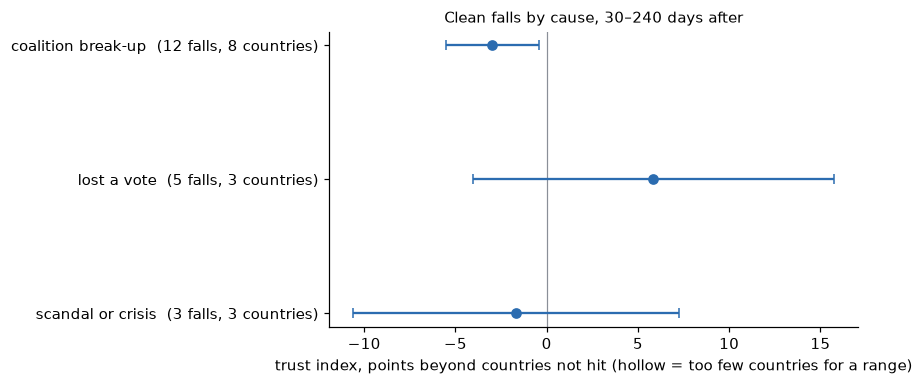

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
cs = by_cause[by_cause.outcome == 'trust_index'].reset_index(drop=True)
y = np.arange(len(cs))[::-1]
ax.axvline(0, color=GREY, lw=0.8)
for yi, r in zip(y, cs.itertuples()):
    if pd.notna(r.ci_low):
        ax.errorbar(r.effect, yi, xerr=[[r.effect - r.ci_low], [r.ci_high - r.effect]], fmt='o', color=BLUE, capsize=3)
    else:
        ax.plot(r.effect, yi, 'o', mfc='white', color=BLUE)
ax.set_yticks(y, [f"{r.group}  ({r.events} falls, {r.countries} countries)" for r in cs.itertuples()])
ax.set_xlabel('trust index, points beyond countries not hit (hollow = too few countries for a range)')
ax.set_title('Clean falls by cause, 30–240 days after', fontsize=10)
plt.tight_layout()
plt.show()

## 7. The individual falls

Every clean fall behind the averages, so a reader can see which ones drive them. Effects are points beyond countries not hit; blank means the panel could not supply that outcome (a missing item or fewer than 5 comparison countries).

In [11]:
cols = ['episode', 'cause', 'after_gap_days'] + list(OUT)
display(ev_clean[cols].sort_values(['cause', 'episode']).round(1).set_index('episode').rename(columns=OUT))
dropped = ev_all[ev_all.not_clean_because != ''][['episode', 'cause', 'not_clean_because', 'trust_index', 'swd']].round(1)
print(f'Not clean ({len(dropped)} falls), for reference:')
display(dropped.set_index('episode').rename(columns={'trust_index': 'Trust index', 'swd': 'Satisfied with democracy'}))

,cause,after_gap_days,Trust index,Trust in government,Trust in parliament,Trust in parties,Satisfied with democracy
episode,,,,,,,
BEL_201812_Michel,coalition break-up,101,-6.8,-8.3,-9.2,-3.0,-5.2
EST_202206_Kallas,coalition break-up,237,-7.4,-11.1,-8.9,-2.3,-4.5
HRV_201706_Plenkovic,coalition break-up,196,NaN,-10.4,NaN,NaN,NaN
HUN_200804_Gyurcsany,coalition break-up,173,-2.7,-2.2,-2.2,-3.7,NaN
ITA_201402_Letta,coalition break-up,107,2.1,5.5,2.5,-1.9,-4.2
ITA_202102_Conte,coalition break-up,44,3.5,4.5,2.9,3.0,13.5
NLD_200607_Balkenende,coalition break-up,82,4.5,9.4,2.7,1.5,NaN
NLD_202506_Schoof,coalition break-up,139,-8.7,-5.5,-12.5,-8.0,-11.6
POL_200708_Kaczynski,coalition break-up,92,1.8,3.5,0.2,NaN,NaN


Not clean (17 falls), for reference:


,cause,not_clean_because,Trust index,Satisfied with democracy
episode,,,,
AUT_2019_Ibiza,scandal or crisis,election,-5.5,-5.4
BGR_2022_Petkov,lost a vote,election,-5.7,-1.7
DEU_202411_Scholz,coalition break-up,election,1.2,3.9
IRL_201101_Cowen,coalition break-up,election,22.3,NaN
ITA_2012_Monti,scandal or crisis,election,1.1,4.3
LTU_200607_Brazauskas,coalition break-up,other cabinet ending,1.6,NaN
LUX_2013_SREL,scandal or crisis,election,-4.9,-2.7
LVA_200604_Kalvitis,coalition break-up,election,0.1,NaN
LVA_201003_Dombrovskis,coalition break-up,other cabinet ending,8.0,NaN


## 8. The dashboard's inputs: days, earlier falls, early election, waves after

The dashboard panel **"Set the shock"** has four inputs. This section estimates the effect of each one with the cleaner measure from sections 1–2, so a reading can be made for any setting of them.

| Dashboard input | Variable here | Note |
| --- | --- | --- |
| Days without a full-powered government (slider) | `days_no_gov`, per 100 days | Days from the fall to the next cabinet not coded caretaker or expert (PPEG). **Known only when the crisis ends**, so it is an input in the dashboard but cannot be known on day 0. |
| Cabinet falls in the last 24 months (slider) | `falls_24m` | Early cabinet endings in the 24 months before (PPEG). |
| Ends with an early election (Yes / No) | `early_election` | 1 if a parliamentary election followed within 365 days. |
| Read the effect after (1 to 4 waves) | horizon *h* | The *h*-th Eurobarometer wave starting at least 30 days after the fall (about 6 months apart). |

For each outcome and horizon, one regression across falls:

> effect of the fall (points beyond countries not hit) = **a fall** + **per 100 days without government** + **early election** + **per earlier fall in 24 months** + other cabinet endings in the window

The *effect of the fall* on the left is the exact-timing, two-wave-baseline, countries-not-hit measure from section 2. **Elections are not filtered out here**, because "ends with an early election" is itself an input; other cabinet endings in the window are kept as a control instead of dropped. Standard errors are clustered by country and ranges are 90%. The row at *h* = 0 is the placebo (the wave before the fall); its slider terms should be about zero.

In [12]:
miss = falls.days_until_non_caretaker_cabinet.isna()
falls.loc[miss, 'days_until_non_caretaker_cabinet'] = falls.days_until_non_caretaker_cabinet.median()
print('Days without government imputed (median) for:', ', '.join(falls.loc[miss, 'episode_id']) or 'none')

HORIZONS = [1, 2, 3, 4]
slider_ev = {h: event_effects(WIN_MAIN, 2, False, h=h) for h in HORIZONS}
slider_ev[0] = event_effects(WIN_MAIN, 2, False, placebo=True)

def ols_cluster(y, X, groups):
    # OLS with standard errors clustered by country (CR1).
    Xv, yv = X.to_numpy(float), y.to_numpy(float)
    XtX_inv = np.linalg.pinv(Xv.T @ Xv)
    b = XtX_inv @ Xv.T @ yv
    u = yv - Xv @ b
    meat = sum(np.outer(Xv[groups == g].T @ u[groups == g], Xv[groups == g].T @ u[groups == g]) for g in np.unique(groups))
    n, k, Gc = len(yv), Xv.shape[1], len(np.unique(groups))
    V = XtX_inv @ meat @ XtX_inv * Gc / (Gc - 1) * (n - 1) / (n - k)
    return pd.Series(b, X.columns), pd.DataFrame(V, X.columns, X.columns), Gc

def design(x):
    return pd.DataFrame({'const': 1.0, 'days': x.days_no_gov / 100, 'early_election': x.early_election,
                         'falls_24m': x.falls_24m, 'other_endings': x.other_endings.astype(float)}, index=x.index)

def fit(ev, o):
    x = ev.dropna(subset=[o, 'days_no_gov', 'falls_24m'])
    if len(x) < 12 or x.iso3.nunique() < 8:
        return None
    b, V, Gc = ols_cluster(x[o], design(x), x.iso3.to_numpy())
    return {'b': b, 'V': V, 'G': Gc, 'n': len(x)}

models = {(o, h): fit(slider_ev[h], o) for o in OUT for h in [0] + HORIZONS}

def reading(model, days, falls24, early):
    x = pd.Series(0.0, index=model['b'].index)
    x['const'], x['days'], x['early_election'], x['falls_24m'] = 1, days / 100, early, falls24
    m, se = float(x @ model['b']), float(np.sqrt(x @ model['V'] @ x))
    c = t90(model['G'] - 1)
    return m, m - c * se, m + c * se

print({h: len(slider_ev[h]) for h in [0] + HORIZONS}, '<- falls with a usable window at each horizon (0 = placebo)')

Days without government imputed (median) for: NLD_202506_Schoof


{0: 40, 1: 40, 2: 37, 3: 35, 4: 37} <- falls with a usable window at each horizon (0 = placebo)


### The screenshot's setting: 60 days, 1 earlier fall, no early election

The reading the dashboard would show for the panel as set in the screenshot, for every horizon. **h = 2 is "2 waves (~1 year)"**. The row *before* is the placebo.

In [13]:
DAYS, FALLS24, EARLY = 60, 1, 0
rows = []
for o in OUT:
    row = {'Outcome': OUT[o]}
    for h in [0] + HORIZONS:
        mdl = models[(o, h)]
        if mdl is None:
            row['before (placebo)' if h == 0 else f'h = {h}'] = 'too few falls'
            continue
        m, lo, hi = reading(mdl, DAYS, FALLS24, EARLY)
        row['before (placebo)' if h == 0 else f'h = {h}'] = f"{m:+.1f} ({lo:+.1f} to {hi:+.1f})"
    row['falls at h = 2'] = f"{models[(o, 2)]['n']} / {slider_ev[2].iso3.nunique()} countries" if models[(o, 2)] else '–'
    rows.append(row)
reading_tab = pd.DataFrame(rows).set_index('Outcome')
print(f'Reading for {DAYS} days without full government, {FALLS24} earlier fall, early election = {"yes" if EARLY else "no"}; points, 90% range:')
display(reading_tab)

Reading for 60 days without full government, 1 earlier fall, early election = no; points, 90% range:


,before (placebo),h = 1,h = 2,h = 3,h = 4,falls at h = 2
Outcome,,,,,,
Trust index,+0.3 (-1.4 to +1.9),+1.0 (-1.7 to +3.6),+0.8 (-2.6 to +4.1),-2.3 (-6.6 to +2.0),-1.7 (-5.9 to +2.6),35 / 21 countries
Trust in government,-1.3 (-3.1 to +0.4),-0.8 (-3.7 to +2.1),-1.3 (-5.1 to +2.4),-3.5 (-8.7 to +1.7),-3.8 (-9.5 to +1.9),37 / 21 countries
Trust in parliament,+0.1 (-1.4 to +1.6),+0.4 (-2.5 to +3.4),-0.1 (-3.6 to +3.4),-1.6 (-5.8 to +2.7),-1.2 (-5.5 to +3.1),35 / 21 countries
Trust in parties,+0.7 (-0.4 to +1.8),+1.4 (-2.3 to +5.2),+2.8 (-0.6 to +6.3),+0.9 (-2.0 to +3.9),+1.1 (-0.8 to +3.1),26 / 21 countries
Satisfied with democracy,+1.2 (-1.6 to +4.0),+1.7 (-2.0 to +5.4),+2.8 (-1.2 to +6.8),+1.9 (-2.4 to +6.2),+1.2 (-3.0 to +5.3),21 / 21 countries


### Effect per unit of each input (what the dashboard's sliders add)

The effect of moving each input by one unit, as in `s1_effects.csv`. The reading for a scenario is the **sum of the terms** that apply (the table above does that sum with the correct joint range). Shown for the first and second wave after, the two most used in the dashboard.

In [14]:
LABEL = {'const': 'A fall (base effect)', 'days': 'Per 100 days without full government', 'early_election': 'Ends with an early election',
         'falls_24m': 'Per earlier fall in the past 24 months', 'other_endings': 'Control: other cabinet endings in the window'}
c90 = lambda mdl: t90(mdl['G'] - 1)
for h in [1, 2]:
    rows = {}
    for o in OUT:
        mdl = models[(o, h)]
        if mdl is None: continue
        rows[OUT[o]] = {LABEL[t]: f"{mdl['b'][t]:+.1f} ({mdl['b'][t] - c90(mdl) * np.sqrt(mdl['V'].loc[t, t]):+.1f} to {mdl['b'][t] + c90(mdl) * np.sqrt(mdl['V'].loc[t, t]):+.1f})"
                        for t in LABEL}
    print(f'h = {h} ({"first" if h == 1 else "second"} wave after), points, 90% range:')
    display(pd.DataFrame(rows))

h = 1 (first wave after), points, 90% range:


,Trust index,Trust in government,Trust in parliament,Trust in parties,Satisfied with democracy
A fall (base effect),+2.1 (-2.6 to +6.8),+0.6 (-4.8 to +6.1),+1.0 (-4.0 to +6.0),+2.4 (-2.4 to +7.1),+3.3 (-1.8 to +8.4)
Per 100 days without full government,-0.3 (-1.3 to +0.7),+0.2 (-1.1 to +1.5),-0.4 (-1.3 to +0.6),-0.4 (-1.2 to +0.4),+0.8 (-1.1 to +2.8)
Ends with an early election,+1.3 (-2.2 to +4.9),+2.7 (-2.4 to +7.7),+1.2 (-2.3 to +4.8),-0.5 (-4.2 to +3.1),-2.6 (-7.0 to +1.7)
Per earlier fall in the past 24 months,-0.9 (-4.4 to +2.5),-1.5 (-5.4 to +2.4),-0.4 (-4.1 to +3.4),-0.7 (-3.2 to +1.9),-2.2 (-5.6 to +1.3)
Control: other cabinet endings in the window,-1.2 (-5.8 to +3.3),+1.8 (-3.3 to +6.8),-1.3 (-6.4 to +3.8),-3.8 (-7.1 to -0.5),-1.6 (-5.2 to +2.0)


h = 2 (second wave after), points, 90% range:


,Trust index,Trust in government,Trust in parliament,Trust in parties,Satisfied with democracy
A fall (base effect),-1.6 (-7.1 to +3.8),-4.0 (-9.5 to +1.5),-2.1 (-8.5 to +4.2),+1.7 (-2.2 to +5.7),+1.7 (-4.0 to +7.3)
Per 100 days without full government,+0.4 (-0.7 to +1.5),+0.8 (-0.8 to +2.4),+0.3 (-0.8 to +1.3),+0.1 (-1.1 to +1.4),+0.9 (-1.4 to +3.3)
Ends with an early election,+4.1 (-0.9 to +9.1),+6.1 (-0.4 to +12.5),+4.6 (-0.8 to +10.0),-0.4 (-4.3 to +3.6),-4.5 (-11.1 to +2.1)
Per earlier fall in the past 24 months,+2.2 (-1.3 to +5.7),+2.2 (-1.5 to +5.9),+1.9 (-2.3 to +6.0),+1.0 (-1.0 to +3.1),+0.6 (-4.0 to +5.1)
Control: other cabinet endings in the window,+0.9 (-5.5 to +7.2),+2.1 (-5.3 to +9.6),+2.0 (-4.4 to +8.4),-4.0 (-8.7 to +0.6),-2.5 (-10.2 to +5.2)


### Dose-response: days without a full government

Trust index, 2 waves after, with 1 earlier fall and no early election, over the days slider. Dots are the individual falls (their own effect, not adjusted for the other inputs). The slider should stop at the longest crisis the data have seen; longer than that is extrapolation.

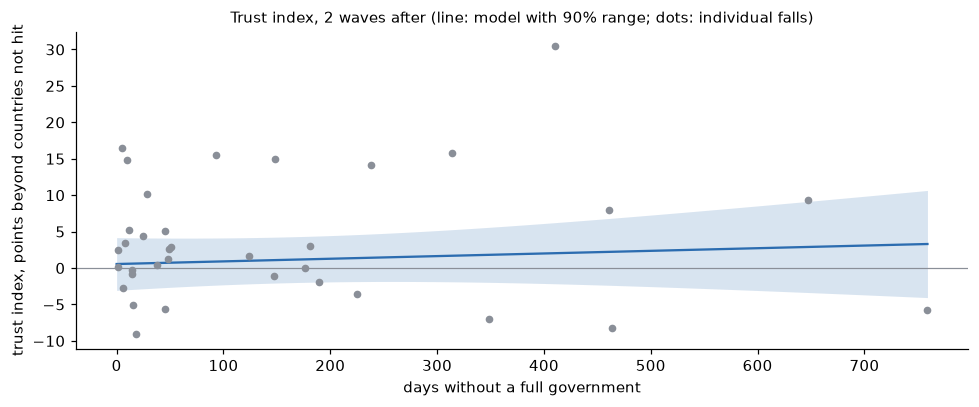

Longest crises in the data (the slider should stop at the first):


,days without full government
episode_id,
HUN_200804_Gyurcsany,759.0
ITA_202102_Conte,647.0
BEL_201812_Michel,464.0
CZE_2009_Topolanek,461.0
HUN_2009_financial_crisis,410.0


Falls in the 24 months before, across the falls: {0: 13, 1: 20, 2: 7, 3: 1}
Share followed by an early election within a year: 59%


In [15]:
mdl = models[('trust_index', 2)]
ev2 = slider_ev[2].dropna(subset=['trust_index'])
DMAX = float(falls.days_until_non_caretaker_cabinet.max())
grid = np.linspace(0, DMAX, 60)
r = np.array([reading(mdl, d, FALLS24, EARLY) for d in grid])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axhline(0, color=GREY, lw=0.8)
ax.fill_between(grid, r[:, 1], r[:, 2], color=BLUE, alpha=0.18, lw=0)
ax.plot(grid, r[:, 0], color=BLUE)
ax.plot(ev2.days_no_gov, ev2.trust_index, 'o', color=GREY, ms=4)
ax.set_xlabel('days without a full government'); ax.set_ylabel('trust index, points beyond countries not hit')
ax.set_title('Trust index, 2 waves after (line: model with 90% range; dots: individual falls)', fontsize=10)
plt.tight_layout(); plt.show()
top = falls.nlargest(5, 'days_until_non_caretaker_cabinet')[['episode_id', 'days_until_non_caretaker_cabinet']]
print('Longest crises in the data (the slider should stop at the first):')
display(top.rename(columns={'days_until_non_caretaker_cabinet': 'days without full government'}).set_index('episode_id'))
print('Falls in the 24 months before, across the falls:', falls.early_endings_24m_before.value_counts().sort_index().to_dict())
print(f"Share followed by an early election within a year: {falls.next_election_gap_days.le(365).mean():.0%}")

### Reliability of the sliders

How many falls stand behind each reading, whether the reading at the screenshot's setting can be told from zero, and whether the **days** slider carries any signal once the two longest crises are set aside (a slope driven by one or two cases is not a slope).

In [16]:
rel = []
for o in OUT:
    for h in HORIZONS:
        mdl = models[(o, h)]
        if mdl is None: continue
        m, lo, hi = reading(mdl, DAYS, FALLS24, EARLY)
        pm = models[(o, 0)]
        pl = reading(pm, DAYS, FALLS24, EARLY) if pm else None
        d_ = mdl['b']['days']; dse = np.sqrt(mdl['V'].loc['days', 'days'])
        rel.append({'Outcome': OUT[o], 'h': h, 'Falls': mdl['n'], 'Countries': mdl['G'],
                    'Reading (screenshot setting)': f"{m:+.1f} ({lo:+.1f} to {hi:+.1f})",
                    'Reading': 'range excludes zero' if (lo > 0 or hi < 0) else 'no detectable change',
                    'Days slope per 100 d': f"{d_:+.2f} ({d_ - c90(mdl) * dse:+.2f} to {d_ + c90(mdl) * dse:+.2f})",
                    'Placebo clean?': 'n/a' if pl is None else ('yes' if pl[1] <= 0 <= pl[2] else f'no ({pl[0]:+.1f})')})
rel = pd.DataFrame(rel)
display(rel)

longest = falls.nlargest(2, 'days_until_non_caretaker_cabinet').episode_id.tolist()
chk = []
for o in ['trust_index', 'trust_parl', 'swd']:
    full = models[(o, 2)]
    sub = fit(slider_ev[2][~slider_ev[2].episode.isin(longest)], o)
    if full is None or sub is None: continue
    f = lambda m: f"{m['b']['days']:+.2f} ({m['b']['days'] - c90(m) * np.sqrt(m['V'].loc['days', 'days']):+.2f} to {m['b']['days'] + c90(m) * np.sqrt(m['V'].loc['days', 'days']):+.2f})"
    chk.append({'Outcome': OUT[o], 'Days slope per 100 d, all falls': f(full), f"without {', '.join(longest)}": f(sub)})
print('Days slope at h = 2 with and without the two longest crises:')
display(pd.DataFrame(chk).set_index('Outcome'))

,Outcome,h,Falls,Countries,Reading (screenshot setting),Reading,Days slope per 100 d,Placebo clean?
0,Trust index,1,37,21,+1.0 (-1.7 to +3.6),no detectable change,-0.26 (-1.25 to +0.74),yes
1,Trust index,2,35,20,+0.8 (-2.6 to +4.1),no detectable change,+0.36 (-0.75 to +1.47),yes
2,Trust index,3,33,17,-2.3 (-6.6 to +2.0),no detectable change,+1.27 (+0.21 to +2.34),yes
3,Trust index,4,35,19,-1.7 (-5.9 to +2.6),no detectable change,+1.34 (-0.98 to +3.67),yes
4,Trust in government,1,40,22,-0.8 (-3.7 to +2.1),no detectable change,+0.17 (-1.11 to +1.46),yes
5,Trust in government,2,37,21,-1.3 (-5.1 to +2.4),no detectable change,+0.80 (-0.76 to +2.36),yes
6,Trust in government,3,35,18,-3.5 (-8.7 to +1.7),no detectable change,+1.50 (+0.24 to +2.76),yes
7,Trust in government,4,37,20,-3.8 (-9.5 to +1.9),no detectable change,+1.72 (-0.83 to +4.27),yes
8,Trust in parliament,1,37,21,+0.4 (-2.5 to +3.4),no detectable change,-0.35 (-1.34 to +0.63),yes
9,Trust in parliament,2,35,20,-0.1 (-3.6 to +3.4),no detectable change,+0.28 (-0.75 to +1.31),yes


Days slope at h = 2 with and without the two longest crises:


,"Days slope per 100 d, all falls","without HUN_200804_Gyurcsany, ITA_202102_Conte"
Outcome,,
Trust index,+0.36 (-0.75 to +1.47),+0.81 (-2.11 to +3.73)
Trust in parliament,+0.28 (-0.75 to +1.31),+0.43 (-2.38 to +3.25)
Satisfied with democracy,+0.94 (-1.39 to +3.27),-1.64 (-4.55 to +1.26)


## 9. Tables for the dashboard

Written to `outputs/model/` as `s1b_*` so that the first notebook's `s1_*` files, which the dashboard reads, are not overwritten:

- `s1b_effects.csv`: sample × window × outcome: average effect, 90% range, events, countries.
- `s1b_events.csv`: one row per fall with its effect on every outcome, cause, timing gap and whether it was clean.
- `s1b_slider_effects.csv`: the dashboard inputs of section 8, in the same layout as `s1_effects.csv` (shock, parameter, outcome, horizon, effect per unit, 90% range, falls, `estimated_without = FRA`). The *days* term is stored **per day**, as in the first notebook. Horizon 0 is the placebo.
- `s1b_slider_reading.csv`: the reading at the screenshot's setting (60 days, 1 earlier fall, no early election) for every outcome and horizon.

In [17]:
parts = []
def add(sample, window, summ):
    parts.append(summ.rename(columns={'group': 'cause_group'}).assign(sample=sample, window=window))
add('clean', '30-240d', main.assign(group='all causes'))
add('clean', '30-240d', by_cause)
add('all falls', '30-240d', all_c.assign(group='all causes'))
add('clean', '240-420d', late.assign(group='all causes'))
add('clean, placebo', 'wave before', plc.assign(group='all causes'))
out = pd.concat(parts)[['sample', 'window', 'cause_group', 'outcome', 'effect', 'ci_low', 'ci_high', 'events', 'countries']]
out.round(3).to_csv(OUTDIR / 's1b_effects.csv', index=False)
ev_all.assign(clean=ev_all.not_clean_because == '', event_date=ev_all.event_date.dt.strftime('%Y-%m-%d')).round(3).to_csv(OUTDIR / 's1b_events.csv', index=False)
PARAM = {'const': ('fall', 1), 'days': ('days_no_gov', 100), 'early_election': ('early_election', 1), 'falls_24m': ('falls_24m', 1), 'other_endings': ('other_endings', 1)}
srows, rrows = [], []
for (o, h), mdl in models.items():
    if mdl is None: continue
    for t, (name, scale) in PARAM.items():
        se = np.sqrt(mdl['V'].loc[t, t]); b_ = mdl['b'][t]; c_ = c90(mdl)
        srows.append({'shock': 'S1', 'parameter': name, 'outcome': o, 'horizon': h, 'effect_per_unit': b_ / scale, 'ci_low': (b_ - c_ * se) / scale,
                      'ci_high': (b_ + c_ * se) / scale, 'n_events': mdl['n'], 'n_obs': mdl['n'], 'estimated_without': HELD_OUT})
    m_, lo_, hi_ = reading(mdl, DAYS, FALLS24, EARLY)
    rrows.append({'outcome': o, 'horizon': h, 'days_no_gov': DAYS, 'falls_24m': FALLS24, 'early_election': EARLY, 'reading': m_, 'ci_low': lo_, 'ci_high': hi_, 'n_events': mdl['n']})
pd.DataFrame(srows).round(4).to_csv(OUTDIR / 's1b_slider_effects.csv', index=False)
pd.DataFrame(rrows).round(3).to_csv(OUTDIR / 's1b_slider_reading.csv', index=False)
print('Wrote', ', '.join(p.name for p in sorted(OUTDIR.glob('s1b_*'))))

Wrote s1b_effects.csv, s1b_events.csv, s1b_slider_effects.csv, s1b_slider_reading.csv


## 10. What this says, and what it does not

In [18]:
def pick(df, o, g='all'):
    return df[(df.outcome == o) & (df.group == g)].iloc[0]
lines = ['**What the cleaner measure says**', '']
m = pick(main, 'trust_index')
lines.append(f"- **{m.events} clean falls in {m.countries} countries** stand behind the headline numbers; {len(ev_all) - len(ev_clean)} of the {len(ev_all)} falls with a usable window were dropped because an election or another cabinet ending fell in the same window.")
for o in OUT:
    r = pick(main, o)
    verdict = 'range excludes zero' if (r.ci_low > 0 or r.ci_high < 0) else 'no detectable change'
    bound = max(abs(r.ci_low), abs(r.ci_high))
    lines.append(f"- **{OUT[o]}**: {r.effect:+.1f} points (90% range {r.ci_low:+.1f} to {r.ci_high:+.1f}), *{verdict}*; effects larger than about {bound:.0f} points are ruled out.")
bad = plc[(plc.ci_low > 0) | (plc.ci_high < 0)]
lines.append("- **Placebo:** " + ('clean for every outcome.' if bad.empty else 'not clean for ' + ', '.join(OUT[o] for o in bad.outcome) + ': trust was already moving before those falls.'))
ci = by_cause[(by_cause.group == 'coalition break-up') & (by_cause.outcome == 'trust_index')].iloc[0]
cp = by_cause[(by_cause.group == 'coalition break-up') & (by_cause.outcome == 'trust_parl')].iloc[0]
pp = plc_c[(plc_c.group == 'coalition break-up') & (plc_c.outcome == 'trust_parl')].iloc[0]
pg = plc_c[(plc_c.group == 'coalition break-up') & (plc_c.outcome == 'trust_gov')].iloc[0]
lines.append(f"- **By cause (exploratory):** coalition break-ups move the trust index by {ci.effect:+.1f} points (range {ci.ci_low:+.1f} to {ci.ci_high:+.1f}, {ci.events} falls in {ci.countries} countries); lost-vote and scandal groups are too small to read.")
lines.append(f"  - Trust in **parliament** after coalition break-ups: {cp.effect:+.1f} (range {cp.ci_low:+.1f} to {cp.ci_high:+.1f}), with a placebo of {pp.effect:+.1f} (range {pp.ci_low:+.1f} to {pp.ci_high:+.1f}). This is the most robust lead (its range excludes zero whichever country is dropped), but it is one of 15 exploratory ranges, so it needs new data to confirm.")
lines.append(f"  - Trust in **government** after coalition break-ups looks similar, but its placebo is {pg.effect:+.1f} (range {pg.ci_low:+.1f} to {pg.ci_high:+.1f}): trust was already falling before these falls, as in the first notebook. Do not read it as an effect of the fall.")
# Dashboard inputs (section 8)
terms = [(o, h, t) for o in OUT for h in HORIZONS if models[(o, h)] for t in ['days', 'early_election', 'falls_24m']]
def excl(o, h, t):
    mdl = models[(o, h)]; b_, se_ = mdl['b'][t], np.sqrt(mdl['V'].loc[t, t]); c_ = c90(mdl)
    return b_ - c_ * se_ > 0 or b_ + c_ * se_ < 0
hits = [(o, h, t) for o, h, t in terms if excl(o, h, t)]
shown = [(o, h) for o in OUT for h in HORIZONS if models[(o, h)]]
read_hits = [(o, h) for o, h in shown if (lambda r: r[1] > 0 or r[2] < 0)(reading(models[(o, h)], DAYS, FALLS24, EARLY))]
lines += ['', '**The dashboard inputs (section 8)**', '',
          f"- At the screenshot's setting ({DAYS} days, {FALLS24} earlier fall, no early election) the reading is distinguishable from zero in **{len(read_hits)} of {len(shown)}** outcome and horizon combinations.",
          f"- Of {len(terms)} slider-term ranges (days, early election, earlier falls; 5 outcomes; 4 horizons), **{len(hits)}** exclude zero. At a 90% level about {len(terms) * 0.1:.0f} would by chance alone: " + ', '.join(f"{OUT[o]} h={h} {t}" for o, h, t in hits) + '.',
          f"- The days slider reaches {DMAX:.0f} days (the longest crisis in the data); the earlier-falls slider is only supported for 0 to {int(falls.early_endings_24m_before.max())}."]
display(Markdown('\n'.join(lines)))

**What the cleaner measure says**

- **20 clean falls in 11 countries** stand behind the headline numbers; 17 of the 40 falls with a usable window were dropped because an election or another cabinet ending fell in the same window.
- **Trust index**: -0.5 points (90% range -3.5 to +2.5), *no detectable change*; effects larger than about 4 points are ruled out.
- **Trust in government**: -0.1 points (90% range -4.3 to +4.1), *no detectable change*; effects larger than about 4 points are ruled out.
- **Trust in parliament**: -2.6 points (90% range -5.3 to +0.1), *no detectable change*; effects larger than about 5 points are ruled out.
- **Trust in parties**: -0.7 points (90% range -2.3 to +0.8), *no detectable change*; effects larger than about 2 points are ruled out.
- **Satisfied with democracy**: -2.6 points (90% range -5.8 to +0.7), *no detectable change*; effects larger than about 6 points are ruled out.
- **Placebo:** not clean for Trust in government: trust was already moving before those falls.
- **By cause (exploratory):** coalition break-ups move the trust index by -3.0 points (range -5.5 to -0.4, 12 falls in 8 countries); lost-vote and scandal groups are too small to read.
  - Trust in **parliament** after coalition break-ups: -4.2 (range -7.4 to -1.0), with a placebo of -0.4 (range -3.3 to +2.4). This is the most robust lead (its range excludes zero whichever country is dropped), but it is one of 15 exploratory ranges, so it needs new data to confirm.
  - Trust in **government** after coalition break-ups looks similar, but its placebo is -2.8 (range -5.3 to -0.3): trust was already falling before these falls, as in the first notebook. Do not read it as an effect of the fall.

**The dashboard inputs (section 8)**

- At the screenshot's setting (60 days, 1 earlier fall, no early election) the reading is distinguishable from zero in **0 of 20** outcome and horizon combinations.
- Of 60 slider-term ranges (days, early election, earlier falls; 5 outcomes; 4 horizons), **5** exclude zero. At a 90% level about 6 would by chance alone: Trust index h=3 days, Trust index h=3 early_election, Trust in government h=3 days, Trust in government h=3 early_election, Satisfied with democracy h=4 falls_24m.
- The days slider reaches 759 days (the longest crisis in the data); the earlier-falls slider is only supported for 0 to 3.

**What it cannot show**

- **Not a cause.** Comparing with countries not hit removes Europe-wide moves, but a fall and a drop in trust can share a cause (a scandal, a budget fight) that the design does not see. The placebo is the check for trust already sliding.
- **Clean means a selected sample.** Falls followed by an election inside the window are dropped, so their effect is not estimated here. The all-falls estimate sits higher than the clean one (compare steps C and D), which is consistent with an election lifting trust, but the ranges overlap and this notebook does not test it.
- **Small samples.** The headline rests on about 20 falls in about 11 countries; the cause split on single digits. A real effect of a point or two would not show up, and cleaning the sample narrowed the ranges only for some outcomes (see the width table in section 4).
- **Exploratory split.** The cause groups were fixed after seeing that the pooled result was flat. A group whose range excludes zero is a lead to test on new data, not a result.
- **Still coarse.** Eurobarometer is two waves a year, so "30–240 days" is a window, not a date. A 9-day crisis cannot be resolved with it.
- **The days input is not known on day 0.** The dashboard asks for days without a full government, but that is only known when the crisis ends. Using it to make a prediction at the moment of a fall would use information from the future.
- **Slider limits.** The days slider is supported only up to the longest crisis in the data (Hungary 2008–10 here, 759 days, not Belgium 2010–11 as in the dashboard panel; check that panel's source) and earlier falls only for 0 to 3. Dropping the two longest crises changes the sign of the days slope for some outcomes.
- **Not yet in:** day-0 shock size (vote margin, majority shortfall), the months to the next scheduled election, and a back-test of this design against a no-change baseline.